In [1]:

from evo_pathfinding_gen_sm.geometry import Environment, Mount, Grid, Bend, Blob
from evo_pathfinding_gen_sm.rendering.renderer import render_environment, render_phenotype, render_genotype, render_genotype_field, render_flow_field
from evo_pathfinding_gen_sm.genetic_algorithm.genetic_code import Phenotype, Genotype
from evo_pathfinding_gen_sm.pathfinding.grid_pathfinder import GridPathfinder
from evo_pathfinding_gen_sm.pathfinding.prm_pathfinder import PRMPathfinder
import matplotlib.pyplot as plt
import shapely.plotting as plotting
import shapely
import numpy as np
import networkx as nx
import yaml

#with open("config/config.yaml") as f:
#    cfg = yaml.load(f, Loader=yaml.FullLoader)

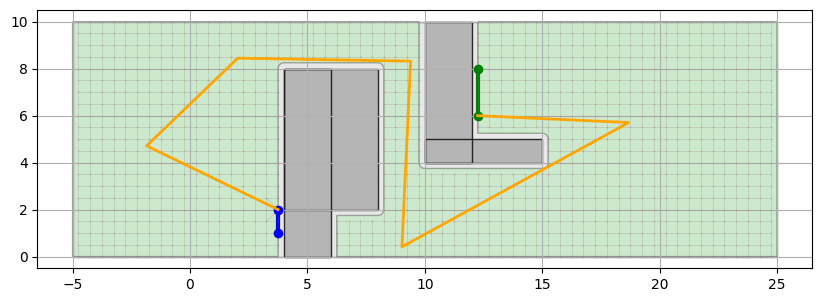

In [ ]:
mount1_plate = shapely.geometry.LineString([(4, 2), (4, 1)])
mount2_plate = shapely.geometry.LineString([(12, 6), (12, 8)])



env = Environment(
    area=(-5, 0, 25, 10),
    obstacles=[
        shapely.geometry.box(10, 4, 12, 10),
        shapely.geometry.box(4, 0, 6, 8),
        shapely.geometry.box(4, 2, 8, 8),
        shapely.geometry.box(10, 4, 15, 5)

    ],
    mount1=Mount(mount1_plate.coords[0], mount1_plate.coords[1], width=0.5),
    mount2=Mount(mount2_plate.coords[0], mount2_plate.coords[1], width=0.5),
    width=0.5
)

bends = []
bends.append(Bend(
    position=shapely.geometry.Point(4-env.width/2,2),
    direction=[0,1],
    previous=None,
    following=None
))
bends.append(Bend(
    position=shapely.geometry.Point(3.5,6),
    direction=[0,1],
    previous=None,
    following=None
))
bends.append(Bend(
    position=shapely.geometry.Point(10,1),
    direction=[1,0],
    previous=None,
    following=None
))
bends.append(Bend(
    position=shapely.geometry.Point(13,4),
    direction=[1,0],
    previous=bends[1],
    following=None
))
bends.append(Bend(
    position=shapely.geometry.Point(12+env.width/2,6),
    direction=[1,0],
    previous=bends[1],
    following=None
))


manual_blobs = [
    Blob(x= bends[0].position.x, y=bends[0].position.y, strength=-17.0, radius=3.0),
    Blob(x= bends[1].position.x, y=bends[1].position.y, strength=-17.0, radius=3.0),
    Blob(x= bends[2].position.x, y=bends[2].position.y, strength=-17.0, radius=3.0),
    Blob(x= bends[3].position.x, y=bends[3].position.y, strength=-17.0, radius=3.5),
    Blob(x= bends[4].position.x, y=bends[4].position.y, strength=-17.0, radius=3.5),

    Blob(x= 8, y=10, strength=17.0, radius=8.5),
]
start_node = next((n for n, d in env.grid.graph.nodes(data=True) if d.get('start')), None)
target_node = next((n for n, d in env.grid.graph.nodes(data=True) if d.get('target')), None)

pathfinder = PRMPathfinder(env)
pathfinder.build_roadmap(node_count=5000000,n = 5000000, radius=800)
path = pathfinder.find_path(start_node, target_node)
render_environment(env,path)

DEBUG: Start Node Degree: 5
No path found.
[]


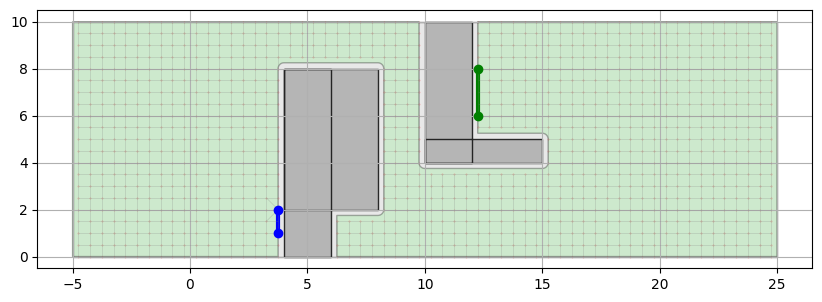

In [3]:
pathfinder = GridPathfinder(env)
path = pathfinder.find_path(start_node, target_node)
print(path)
render_environment(env,path)